# Оценка моделей

Два сценария: ранний (без G1 и G2) и поздний (с G1 и G2). Перед test согласуйте пороги из плана `new/src1/evaluation_plan.md`. Запускайте ячейки по порядку; результаты основаны на небольших выборках и носят исследовательский характер.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / 'src1').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src1').is_dir():
    raise RuntimeError('Запустите notebook из корня проекта или папки notebooks')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from src1.load_split import load_split
from src1.features import make_feature_set
from src1.evaluation import (development_models, evaluate_models, bootstrap_mae, data_quality,
    psi_numeric, group_metrics, importance, local_sensitivity, robustness, zero_grade_errors,
    save_table, diagnostic_plots, plot_importance, partial_dependence, save_figure)

pd.set_option('display.max_columns', None)

## 1. Протокол до test

Согласуйте порог MAE и минимальное улучшение MAE относительно baseline отдельно для двух сценариев. Также задайте пороги MAE для порций и PSI. Это проектные критерии, не значения из методички. Только после согласования впишите числа и установите `confirmed = True`. Повторная настройка порогов после просмотра test делает приёмку необъективной.

In [2]:
confirmed = True
thresholds = {
    'early': {'max_test_mae': 3.0, 'min_mae_improvement': 0.1, 'max_batch_mae': 3.5},
    'late': {'max_test_mae': 2.0, 'min_mae_improvement': 0.3, 'max_batch_mae': 2.0},
    'max_psi': 0.25,
}

if not confirmed:
    raise ValueError('Сначала согласуйте и заполните пороги, затем установите confirmed = True')
values = [thresholds[s][key] for s in ('early', 'late') for key in ('max_test_mae', 'min_mae_improvement', 'max_batch_mae')] + [thresholds['max_psi']]
if any(not isinstance(v, (float, int)) or isinstance(v, bool) or not np.isfinite(v) or v < 0 for v in values):
    raise ValueError('Все пороги должны быть конечными неотрицательными числами')
protocol_file = ROOT / 'reports/tables/model_comparison/evaluation_thresholds.json'
if protocol_file.exists() and json.loads(protocol_file.read_text(encoding='utf-8')) != thresholds:
    raise ValueError('Протокол уже сохранён с другими порогами. Не меняйте их после просмотра test; обсудите изменение отдельно.')
protocol_file.parent.mkdir(parents=True, exist_ok=True)
protocol_file.write_text(json.dumps(thresholds, ensure_ascii=False, indent=2), encoding='utf-8')
print('Пороги зафиксированы:', protocol_file)

Пороги зафиксированы: D:\Project1\student-performance-model\reports\tables\model_comparison\evaluation_thresholds.json


## 2. Загрузка моделей и оценка test

Baseline и дополнительный бустинг обучаются только на train + validation. Бустинг выбирается по ранее сохранённой train CV. Применение test — итоговая оценка, не подбор модели.

In [3]:
if not protocol_file.exists() or not confirmed:
    raise RuntimeError('Сначала выполните ячейку протокола')
train, validation, test = load_split()
development = pd.concat([train, validation])
models, boost_config = development_models(train, validation)
print('Бустинг выбран по предыдущей CV:', boost_config['model'], 'новые признаки:', boost_config['engineered'])
metrics, predictions = evaluate_models(models, test)
display(metrics.round(3))
save_table(metrics, 'model_comparison', 'test_metrics.csv')

Бустинг выбран по предыдущей CV: Boosting leaves=15 rate=0.05 новые признаки: False


,scenario,model,mae,mse,rmse,r2,mae_ci_low,mae_ci_high,n
0,early,selected,3.721,24.864,4.986,0.057,2.748,4.649,48
1,early,baseline,3.750,27.125,5.208,-0.029,2.666,4.792,48
2,late,selected,1.425,5.403,2.324,0.795,0.939,1.990,48
3,late,baseline,3.750,27.125,5.208,-0.029,2.666,4.792,48
4,late,boosting,1.586,6.647,2.578,0.748,1.049,2.249,48


WindowsPath('D:/Project1/student-performance-model/reports/tables/model_comparison/test_metrics.csv')

### Сравнение с baseline и парные интервалы

Разность ниже нуля означает меньшую MAE первой модели. Интервал — приближённый 95% бутстреп-интервал разности; маленький test и несколько сравнений ограничивают выводы.

In [4]:
comparison = []
for scenario in ('early', 'late'):
    baseline = predictions[(scenario, 'baseline')]
    for name in models[scenario]:
        if name == 'baseline':
            continue
        pred = predictions[(scenario, name)]
        lo, hi = bootstrap_mae(test['G3'], pred, other=baseline)
        model_mae = metrics.query('scenario == @scenario and model == @name')['mae'].iloc[0]
        base_mae = metrics.query("scenario == @scenario and model == 'baseline'")['mae'].iloc[0]
        comparison.append({'scenario': scenario, 'model': name, 'delta_mae': model_mae - base_mae, 'ci_low': lo, 'ci_high': hi, 'meets_limits': bool(model_mae <= thresholds[scenario]['max_test_mae'] and base_mae - model_mae >= thresholds[scenario]['min_mae_improvement'])})
lo, hi = bootstrap_mae(test['G3'], predictions[('late', 'selected')], other=predictions[('late', 'boosting')])
print('Late: разность MAE лес − бустинг, 95% интервал:', (lo, hi))
comparison = pd.DataFrame(comparison)
display(comparison.round(3))
save_table(comparison, 'model_comparison', 'test_comparison.csv')

Late: разность MAE лес − бустинг, 95% интервал: (np.float64(-0.32792960096243906), np.float64(-0.005371421374087958))


,scenario,model,delta_mae,ci_low,ci_high,meets_limits
0,early,selected,-0.029,-0.240,0.162,False
1,late,selected,-2.325,-3.187,-1.415,True
2,late,boosting,-2.164,-3.002,-1.295,True


WindowsPath('D:/Project1/student-performance-model/reports/tables/model_comparison/test_comparison.csv')

## 3. Графики и ошибки по группам

Остаток равен фактической оценке минус прогноз. Численность группы важна: ошибки на малых группах нестабильны.

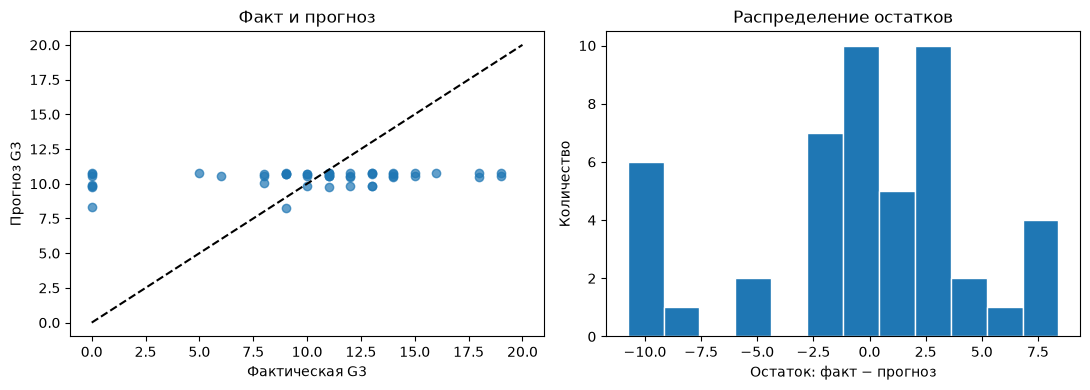

,group,value,n,mae
0,sex,F,24,3.164
1,sex,M,24,4.278
2,school,GP,43,3.601
3,school,MS,5,4.750


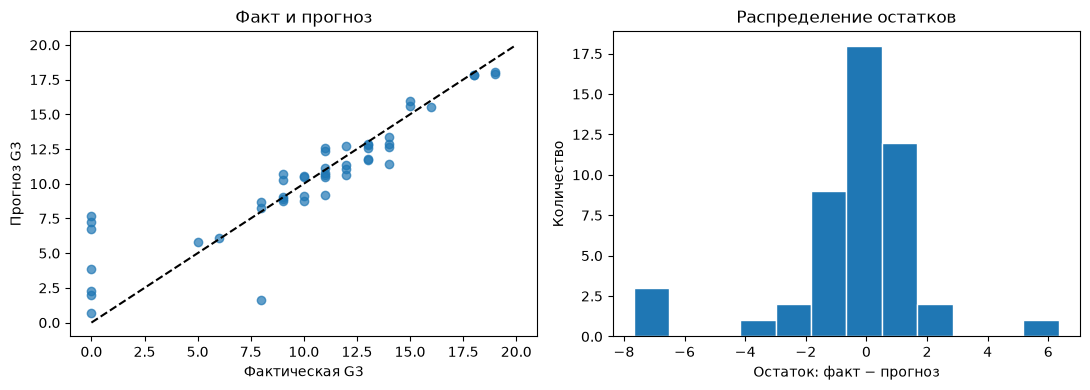

,group,value,n,mae
0,sex,F,24,1.553
1,sex,M,24,1.297
2,school,GP,43,1.478
3,school,MS,5,0.976


In [5]:
for scenario in ('early', 'late'):
    pred = predictions[(scenario, 'selected')]
    diagnostic_plots(test['G3'], pred, scenario)
    plt.show()
    groups = group_metrics(test, pred)
    display(groups.round(3))
    save_table(groups, 'errors', f'{scenario}_groups.csv')
    details = pd.DataFrame({'actual': test['G3'].to_numpy(), 'prediction': pred, 'residual': test['G3'].to_numpy() - pred})
    save_table(details, 'predictions', f'{scenario}_test_predictions.csv')

## 4. Важность и отдельные предсказания

Перестановочная важность показывает изменение MAE при перемешивании исходного признака. На графике частичной зависимости по горизонтали значение признака, по вертикали средний прогноз при его замене у объектов test. Строим не более трёх графиков для числовых признаков с положительной измеренной важностью; если их меньше, графиков тоже будет меньше. Частичная зависимость и локальная замена признака не показывают причинное влияние. Из-за корреляции входов могут получиться нереалистичные сочетания.

,feature,importance,std
14,failures,0.141489,0.051925
0,school,0.000000,0.000000
2,age,0.000000,0.000000
3,address,0.000000,0.000000
4,famsize,0.000000,0.000000
1,sex,0.000000,0.000000
6,Medu,0.000000,0.000000
8,Mjob,0.000000,0.000000
9,Fjob,0.000000,0.000000
10,reason,0.000000,0.000000


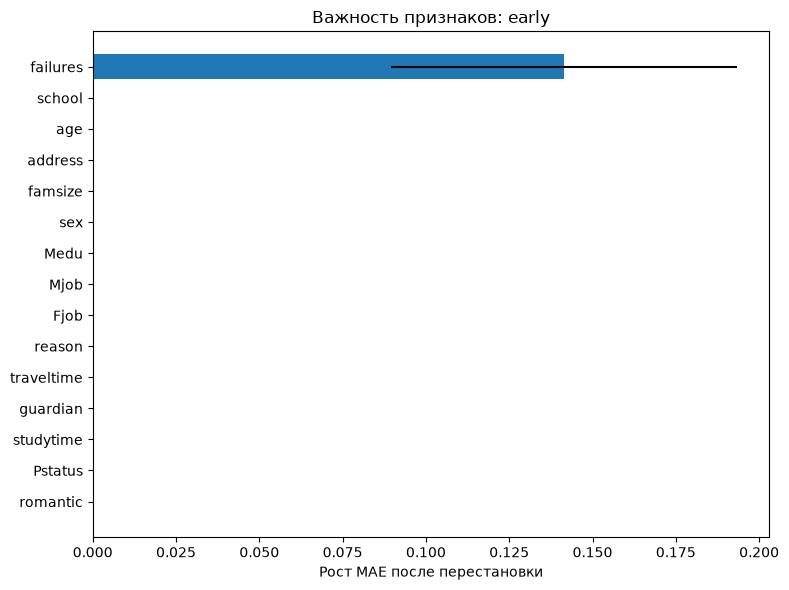

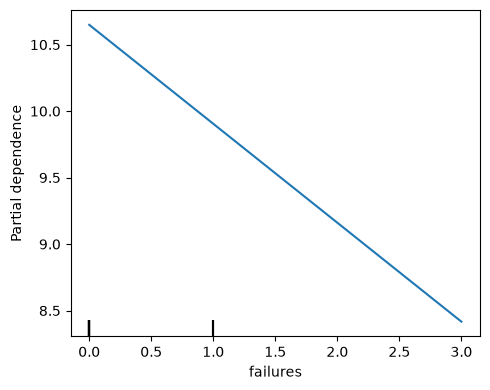

early best факт: 10 прогноз: 9.842508805962979


,feature,original,replacement,prediction,changed_prediction
0,failures,1,0.0,9.842509,10.586518


early worst факт: 0 прогноз: 10.768064278081843


,feature,original,replacement,prediction,changed_prediction
0,failures,0,0.0,10.768064,10.768064


,feature,importance,std
31,G2,3.304101,0.294275
29,absences,0.357700,0.133982
30,G1,0.083762,0.026854
14,failures,0.007763,0.003030
7,Fedu,0.007226,0.010261
28,health,0.006911,0.006229
12,traveltime,0.006886,0.003655
17,paid,0.006244,0.005608
8,Mjob,0.004849,0.003629
24,freetime,0.003029,0.003457


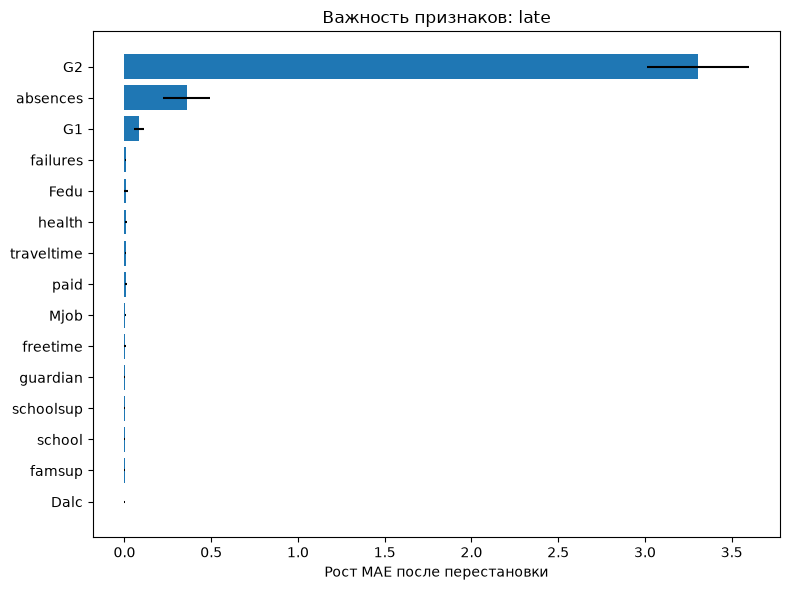

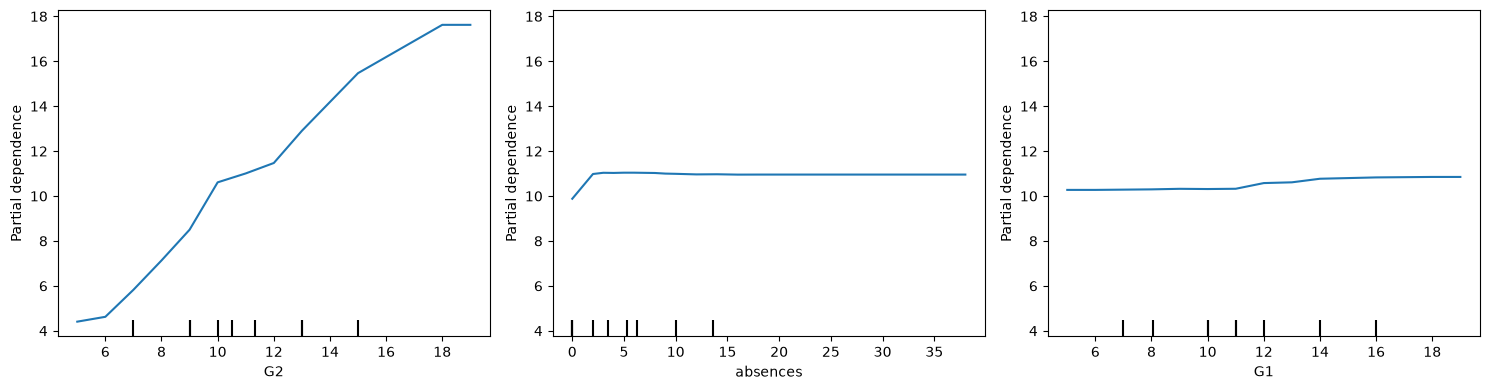

late best факт: 9 прогноз: 9.067904761904762


,feature,original,replacement,prediction,changed_prediction
0,G2,9,11.0,9.067905,10.470333
1,absences,2,4.0,9.067905,9.171238
2,G1,10,10.0,9.067905,9.067905


late worst факт: 0 прогноз: 7.670404761904762


,feature,original,replacement,prediction,changed_prediction
0,G2,9,11.0,7.670405,10.424333
1,absences,0,4.0,7.670405,8.921071
2,G1,10,10.0,7.670405,7.670405


In [6]:
for scenario in ('early', 'late'):
    X, y = make_feature_set(test, use_grades=scenario == 'late')
    X_ref, _ = make_feature_set(development, use_grades=scenario == 'late')
    model = models[scenario]['selected']
    imp = importance(model, X, y)
    display(imp.head(15))
    save_table(imp, 'feature_importance', f'{scenario}_importance.csv')
    plot_importance(imp, scenario)
    plt.show()
    numeric_features = [row.feature for row in imp.itertuples() if row.importance > 0 and pd.api.types.is_numeric_dtype(X[row.feature])][:3]
    if not numeric_features:
        print('Не найдено числовых признаков с положительной важностью')
        continue
    partial_dependence(model, X, numeric_features, scenario)
    plt.show()
    errors = np.abs(y.to_numpy() - predictions[(scenario, 'selected')])
    for label, index in [('best', int(errors.argmin())), ('worst', int(errors.argmax()))]:
        local = local_sensitivity(model, X, X_ref, index, numeric_features)
        print(scenario, label, 'факт:', y.iloc[index], 'прогноз:', predictions[(scenario, 'selected')][index])
        display(local)
        save_table(local, 'feature_importance', f'{scenario}_{label}_local.csv')

## 5. Проверка устойчивости

Изменяем копии данных: добавляем шум с масштабом 10% стандартного отклонения `age` и отдельно создаём пропуски в 10% строк. Это искусственные условия, а не оценка реальной частоты ошибок.

In [7]:
for scenario in ('early', 'late'):
    X, y = make_feature_set(test, use_grades=scenario == 'late')
    result = robustness(models[scenario]['selected'], X, y, feature='age')
    print(scenario)
    display(result.round(3))
    save_table(result, 'data_quality', f'{scenario}_robustness.csv')

early


,feature,condition,changed_rows,mae
0,age,original,0,3.721
1,age,noise_10pct_std,48,3.721
2,age,missing_10pct_rows,4,3.721


late


,feature,condition,changed_rows,mae
0,age,original,0,1.425
1,age,noise_10pct_std,48,1.426
2,age,missing_10pct_rows,4,1.425


## 6. Проверки данных и порции

Проверки сравнивают структуру и категории с development. В демонстрационной копии намеренно испорчено время учёбы. Ошибочные порции не оцениваются; новые категории и дубликаты показываются как предупреждения. PSI рассчитан по `age`, `absences`, `failures`; при малых порциях это только ориентир.

,check,issues,details,blocking
8,range_studytime,1,,True


batch_01 предупреждения и ошибки:


,check,issues,details,blocking


batch_02 предупреждения и ошибки:


,check,issues,details,blocking


batch_03 предупреждения и ошибки:


,check,issues,details,blocking


batch_04 предупреждения и ошибки:


,check,issues,details,blocking


,batch,scenario,model,mae,mse,rmse,r2,mae_ci_low,mae_ci_high,n,mae_warning
0,batch_01,early,selected,3.208,20.527,4.531,0.065,2.237,4.226,40,False
1,batch_01,early,baseline,3.300,22.600,4.754,-0.029,2.300,4.400,40,False
2,batch_01,late,selected,0.883,2.211,1.487,0.899,0.576,1.282,40,False
3,batch_01,late,baseline,3.300,22.600,4.754,-0.029,2.300,4.400,40,True
4,batch_01,late,boosting,0.862,1.926,1.388,0.912,0.573,1.219,40,False
5,batch_02,early,selected,4.255,27.591,5.253,0.035,3.314,5.234,40,True
6,batch_02,early,baseline,4.150,28.650,5.353,-0.002,3.125,5.225,40,True
7,batch_02,late,selected,1.136,4.370,2.090,0.847,0.681,1.707,40,False
8,batch_02,late,baseline,4.150,28.650,5.353,-0.002,3.125,5.225,40,True
9,batch_02,late,boosting,1.337,5.542,2.354,0.806,0.824,1.955,40,False


,batch,feature,psi,warning
0,batch_01,age,0.122,False
1,batch_01,absences,0.016,False
2,batch_01,failures,0.211,False
3,batch_02,age,0.068,False
4,batch_02,absences,0.063,False
5,batch_02,failures,0.224,False
6,batch_03,age,0.112,False
7,batch_03,absences,0.027,False
8,batch_03,failures,0.188,False
9,batch_04,age,0.280,True


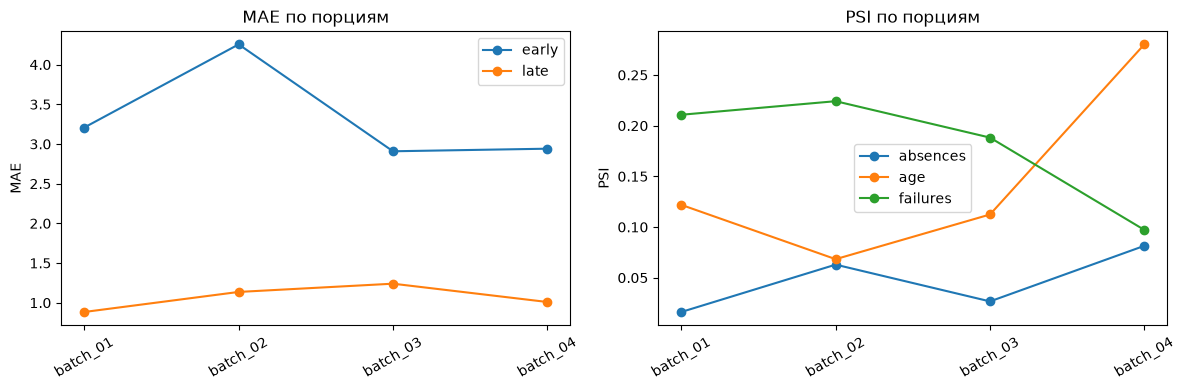

In [8]:
broken = development.head(3).copy()
broken.iloc[0, broken.columns.get_loc('studytime')] = 99
quality_demo = data_quality(broken, development)
display(quality_demo[quality_demo['issues'] > 0])
save_table(quality_demo, 'data_quality', 'quality_demo.csv')
batch_rows, psi_rows = [], []
for path in sorted((ROOT / 'data/incoming').glob('batch_*.csv')):
    batch = pd.read_csv(path)
    quality = data_quality(batch, development)
    save_table(quality, 'data_quality', f'{path.stem}_quality.csv')
    print(path.stem, 'предупреждения и ошибки:')
    display(quality[quality['issues'] > 0])
    if quality['blocking'].any():
        print('Порция не оценивается до исправления данных')
        continue
    batch_metrics, _ = evaluate_models(models, batch)
    batch_metrics.insert(0, 'batch', path.stem)
    batch_rows.append(batch_metrics)
    for feature in ('age', 'absences', 'failures'):
        value = psi_numeric(development[feature], batch[feature])
        psi_rows.append({'batch': path.stem, 'feature': feature, 'psi': value, 'warning': bool(value > thresholds['max_psi'])})
if batch_rows:
    batch_metrics = pd.concat(batch_rows, ignore_index=True)
    batch_metrics['mae_warning'] = [row.mae > thresholds[row.scenario]['max_batch_mae'] for row in batch_metrics.itertuples()]
    psi_table = pd.DataFrame(psi_rows)
    display(batch_metrics.round(3), psi_table.round(3))
    save_table(batch_metrics, 'model_comparison', 'batch_metrics.csv')
    save_table(psi_table, 'data_quality', 'batch_psi.csv')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    selected = batch_metrics[batch_metrics['model'] == 'selected']
    for scenario, part in selected.groupby('scenario'):
        axes[0].plot(part['batch'], part['mae'], marker='o', label=scenario)
    for feature, part in psi_table.groupby('feature'):
        axes[1].plot(part['batch'], part['psi'], marker='o', label=feature)
    axes[0].set(title='MAE по порциям', ylabel='MAE')
    axes[1].set(title='PSI по порциям', ylabel='PSI')
    for ax in axes:
        ax.legend()
        ax.tick_params(axis='x', rotation=30)
    save_figure(fig, 'data_quality', 'batch_metrics_psi.png')
    plt.show()

## 7. Дополнительные проверки

Следующие проверки добавлены после первого просмотра test, поэтому они исследовательские. Сохранённые выше старые outputs, особенно PSI для `failures`, необходимо пересчитать: перезапустите ядро и выполните все ячейки по порядку. Шум рассчитывается по development; оценки и число неудач округляются и ограничиваются допустимым диапазоном.

In [9]:
for scenario, features in [('early', ['failures']), ('late', ['G2', 'absences'])]:
    X, y = make_feature_set(test, use_grades=scenario == 'late')
    X_ref, _ = make_feature_set(development, use_grades=scenario == 'late')
    pieces = [robustness(models[scenario]['selected'], X, y, feature=feature, reference=X_ref) for feature in features]
    result = pd.concat(pieces, ignore_index=True)
    print(scenario, ': изменённые строки и MAE')
    display(result.round(3))
    save_table(result, 'data_quality', f'{scenario}_important_features_robustness.csv')

early : изменённые строки и MAE


,feature,condition,changed_rows,mae
0,failures,original,0,3.721
1,failures,noise_10pct_std,0,3.721
2,failures,missing_10pct_rows,4,3.721
3,failures,discrete_step_10pct_rows,4,3.783


late : изменённые строки и MAE


,feature,condition,changed_rows,mae
0,G2,original,0,1.425
1,G2,noise_10pct_std,2,1.455
2,G2,missing_10pct_rows,4,1.590
3,absences,original,0,1.425
4,absences,noise_10pct_std,19,1.442
5,absences,missing_10pct_rows,4,1.434


### Ошибки при нулевой оценке

Сравниваем MAE и средний прогноз для строк с `G3 = 0` и `G3 > 0`. Это не выясняет причину нулей: перед предметными выводами требуется проверить документацию датасета.

In [10]:
for scenario in ('early', 'late'):
    summary = zero_grade_errors(test['G3'], predictions[(scenario, 'selected')])
    print(scenario)
    display(summary.round(3))
    save_table(summary, 'errors', f'{scenario}_zero_grade_errors.csv')

early


,group,n,mae,mean_prediction
0,G3 = 0,7,9.988,9.988
1,G3 > 0,41,2.651,10.490


late


,group,n,mae,mean_prediction
0,G3 = 0,7,4.347,4.347
1,G3 > 0,41,0.927,11.480


## 8. Предварительное решение

Ранняя модель не выполнила критерии на test. Поздний лес прошёл численные пороги, но из-за малого набора, крупных индивидуальных ошибок и доступности признаков его нельзя применять как единственное основание решений о студенте. Дополнительные проверки и исправленный PSI нужно обсудить после запуска; окончательное решение и отчёт пока не оформлены.